# Exploration du dataset ASVspoof2019 LA

On regroupe ici tout ce qu'on a fait chacun de son côté sur l'exploration du dataset (Kenza, Dhruv, Yasser, Yanis), avant de passer à l'entraînement.

On veut répondre à trois questions avant d'écrire la moindre ligne de `features.py` :
1. C'est quoi exactement un fichier de ce dataset (format, codec, structure du signal) ?
2. Est-ce qu'on peut faire confiance au dataset (pas de fuite entre splits, pas de doublons) ?
3. À quoi ressemble un bonafide et un spoof, dans le temps et en fréquence ?

On garde les splits officiels : train, validation, test (eval).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torchaudio
import librosa
import soundfile as sf
import io

from datasets import load_dataset, Audio
from IPython.display import Audio as IPyAudio, display

sns.set_theme(style="whitegrid")

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

print("CUDA disponible :", torch.cuda.is_available())
print("PyTorch :", torch.__version__)


/home/docker/speech-deepfake-detection/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CUDA disponible : True
PyTorch : 2.5.1+cu124


## 1. C'est quoi un fichier audio dans ce dataset

Avant de coder, il faut comprendre ce qu'on manipule. Un fichier audio numérique, c'est trois choses :
- une fréquence d'échantillonnage (combien de mesures par seconde, ici 16 000 Hz, donc 16 000 valeurs par seconde) ;
- un format de stockage (ici du FLAC, un codec compressé mais sans perte) ;
- une fois décodé, une suite de nombres (les échantillons).

Les fichiers sont stockés compressés en FLAC. Il faut les décoder pour les manipuler comme un tableau de nombres classique. La librairie `datasets` le fait toute seule derrière, mais on le fait une fois à la main ci-dessous pour voir ce qui se passe réellement.


In [2]:
from pathlib import Path

DATASET_NAME = "Bisher/ASVspoof_2019_LA"

# Sur le serveur de l'école, le dataset est déjà téléchargé dans ce cache.
# Si tu lances ce notebook ailleurs, adapte PROJECT_ROOT.
PROJECT_ROOT = Path.cwd()
CACHE_DIR = PROJECT_ROOT / "data" / "huggingface_cache"

ds = load_dataset(DATASET_NAME, cache_dir=str(CACHE_DIR) if CACHE_DIR.exists() else None)
print(ds)


DatasetDict({
    train: Dataset({
        features: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'],
        num_rows: 25380
    })
    validation: Dataset({
        features: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'],
        num_rows: 24844
    })
    test: Dataset({
        features: ['speaker_id', 'audio_file_name', 'audio', 'system_id', 'key'],
        num_rows: 71237
    })
})


In [3]:
# On désactive le décodage automatique pour voir le fichier brut
train_raw = ds["train"].cast_column("audio", Audio(decode=False))

idx = 0
ex = train_raw[idx]
audio = ex["audio"]

print("Label (key) :", ex["key"], "-> 0 = bonafide, 1 = spoof")
print("Métadonnées brutes :", {k: v for k, v in audio.items() if k != "bytes"})

# Décodage à la main avec soundfile
if audio["bytes"] is not None:
    samples, sr = sf.read(io.BytesIO(audio["bytes"]), dtype="float32")
else:
    samples, sr = sf.read(audio["path"], dtype="float32")

print("\nAprès décodage :")
print("Sampling rate :", sr, "Hz")
print("Nombre d'échantillons :", len(samples))
print("Durée :", len(samples) / sr, "s")
print("Quelques valeurs :", samples[10000:10010])


Label (key) : 0 -> 0 = bonafide, 1 = spoof
Métadonnées brutes : {'path': 'LA_T_1138215.flac'}

Après décodage :
Sampling rate : 16000 Hz
Nombre d'échantillons : 55329
Durée : 3.4580625 s
Quelques valeurs : [ 0.00045776  0.00247192  0.00115967 -0.00201416 -0.00265503 -0.00170898
 -0.0010376  -0.00064087  0.00067139 -0.00027466]


## 2. Ce que contient le dataset

3 splits, normalement disjoints : `train`, `validation`, `test` (eval). Colonnes disponibles : `speaker_id`, `audio_file_name`, `audio`, `system_id`, `key`.

Attention, `key` n'est pas un texte "bonafide"/"spoof", c'est un entier. `key=0` veut dire bonafide, `key=1` veut dire spoof. On a vérifié ça en comparant avec `system_id='-'` (aucune attaque), qui tombe exactement sur le même nombre de lignes que `key=0`.


In [4]:
metadata_columns = ["speaker_id", "audio_file_name", "system_id", "key"]
metadata = {}

for split in ds.keys():
    metadata[split] = ds[split].select_columns(metadata_columns).to_pandas()
    print(f"{split}: {len(metadata[split])} audios")

metadata["train"].head()


train: 25380 audios
validation: 24844 audios
test: 71237 audios


,speaker_id,audio_file_name,system_id,key
0,LA_0079,LA_T_1138215,-,0
1,LA_0079,LA_T_1271820,-,0
2,LA_0079,LA_T_1272637,-,0
3,LA_0079,LA_T_1276960,-,0
4,LA_0079,LA_T_1341447,-,0


## 3. Déséquilibre des classes

Environ 90% de spoof et 10% de bonafide, et ça reste stable sur les trois splits. Un modèle qui prédit toujours "spoof" aurait donc 90% d'accuracy sans avoir rien appris, donc l'accuracy seule ne sert à rien ici. On va utiliser l'EER (Equal Error Rate) comme métrique principale, en complément du F1 sur la classe bonafide et d'une matrice de confusion.


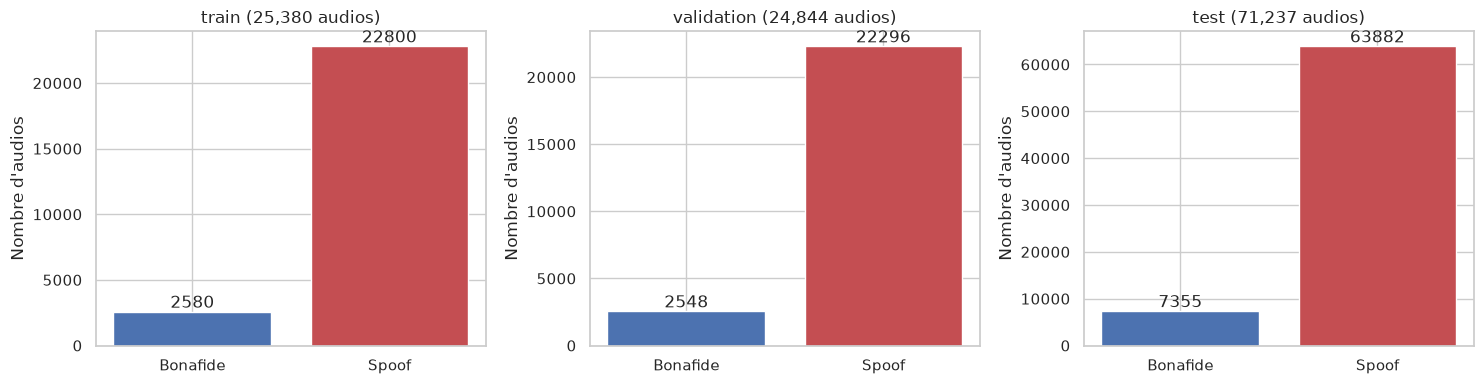

In [5]:
label_names = {0: "Bonafide", 1: "Spoof"}

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (split, df) in zip(axes, metadata.items()):
    counts = df["key"].value_counts().sort_index()
    labels = [label_names[int(k)] for k in counts.index]
    ax.bar(labels, counts.values, color=["#4C72B0", "#C44E52"])
    ax.set_title(f"{split} ({len(df):,} audios)")
    ax.set_ylabel("Nombre d'audios")
    for i, count in enumerate(counts.values):
        ax.text(i, count, str(count), ha="center", va="bottom")
plt.tight_layout()
plt.show()


In [6]:
for split, df in metadata.items():
    print(f"\n{split.upper()}")
    proportions = df["key"].value_counts(normalize=True).sort_index().mul(100).round(2)
    print(proportions.rename(index=label_names))



TRAIN
key
Bonafide    10.17
Spoof       89.83
Name: proportion, dtype: float64

VALIDATION
key
Bonafide    10.26
Spoof       89.74
Name: proportion, dtype: float64

TEST
key
Bonafide    10.32
Spoof       89.68
Name: proportion, dtype: float64


## 4. Les locuteurs sont bien disjoints entre splits

Le protocole officiel dit que les locuteurs ne se recoupent pas entre train, validation et test. On ne le suppose pas, on vérifie.


In [7]:
for split, df in metadata.items():
    speakers = set(df["speaker_id"])
    print(f"{split}: {len(speakers)} locuteurs uniques")


train: 20 locuteurs uniques
validation: 20 locuteurs uniques
test: 67 locuteurs uniques


In [8]:
splits = list(metadata.keys())
for i in range(len(splits)):
    for j in range(i + 1, len(splits)):
        s1, s2 = splits[i], splits[j]
        common = set(metadata[s1]["speaker_id"]) & set(metadata[s2]["speaker_id"])
        status = "OK, aucun recoupement" if not common else f"PROBLEME : {sorted(common)[:10]}"
        print(f"{s1} / {s2} : {len(common)} locuteur(s) en commun -> {status}")


train / validation : 0 locuteur(s) en commun -> OK, aucun recoupement
train / test : 0 locuteur(s) en commun -> OK, aucun recoupement
validation / test : 0 locuteur(s) en commun -> OK, aucun recoupement


## 5. Les attaques connues et inédites sont bien séparées

C'est le point le plus important du dataset : train et validation ne contiennent que les attaques A01 à A06 (connues), et test ne contient que A07 à A19 (jamais vues avant). C'est ce découpage qui permet de mesurer si un modèle généralise à des méthodes de synthèse qu'il n'a jamais rencontrées.


In [9]:
for split, df in metadata.items():
    print(f"\n{split.upper()}")
    attack_counts = df[df["key"] == 1]["system_id"].value_counts().sort_index()
    display(attack_counts.to_frame("Nombre d'audios"))



TRAIN


,Nombre d'audios
system_id,
A01,3800
A02,3800
A03,3800
A04,3800
A05,3800
A06,3800



VALIDATION


,Nombre d'audios
system_id,
A01,3716
A02,3716
A03,3716
A04,3716
A05,3716
A06,3716



TEST


,Nombre d'audios
system_id,
A07,4914
A08,4914
A09,4914
A10,4914
A11,4914
A12,4914
A13,4914
A14,4914
A15,4914


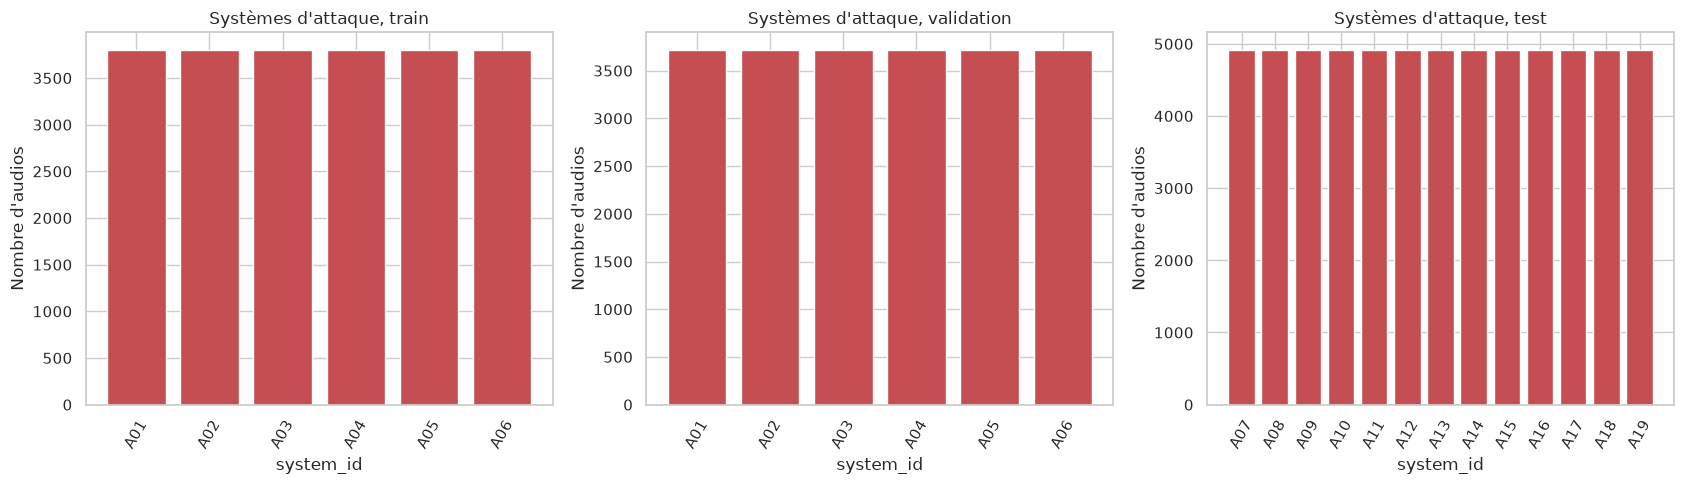

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
for ax, (split, df) in zip(axes, metadata.items()):
    spoof = df[df["key"] == 1]
    counts = spoof["system_id"].value_counts().sort_index()
    ax.bar(counts.index, counts.values, color="#C44E52")
    ax.set_title(f"Systèmes d'attaque, {split}")
    ax.set_xlabel("system_id")
    ax.set_ylabel("Nombre d'audios")
    ax.tick_params(axis="x", rotation=60)
plt.tight_layout()
plt.show()


In [11]:
# Est-ce que chaque locuteur de train a bien été exposé à toutes les attaques connues ?
train_meta = metadata["train"]
pd.crosstab(train_meta["speaker_id"], train_meta["system_id"])


system_id,-,A01,A02,A03,A04,A05,A06
speaker_id,,,,,,,
LA_0079,127,186,186,186,186,186,186
LA_0080,127,186,186,186,186,186,186
LA_0081,127,186,186,186,186,186,186
LA_0082,132,196,196,196,196,196,196
LA_0083,132,196,196,196,196,196,196
LA_0084,127,186,186,186,186,186,186
LA_0085,127,186,186,186,186,186,186
LA_0086,127,186,186,186,186,186,186
LA_0087,127,186,186,186,186,186,186


## 6. Doublons et fichiers bizarres

On vérifie qu'il n'y a pas deux fois le même nom de fichier dans un split.


In [12]:
import collections

for split in ds:
    names = ds[split]["audio_file_name"]
    dup = [n for n, c in collections.Counter(names).items() if c > 1]
    print(f"[{split}] doublons de audio_file_name : {len(dup)}" + (f" (ex : {dup[:5]})" if dup else ""))


[train] doublons de audio_file_name : 0
[validation] doublons de audio_file_name : 0
[test] doublons de audio_file_name : 0


## 7. Vérification du sample rate sur tous les fichiers

Ici on ne vérifie pas juste un échantillon, on passe les 121 461 fichiers un par un. On lit seulement l'en-tête du fichier (pas le son complet), donc ça reste rapide même sur les 71 237 fichiers de test.


In [13]:
def check_all_sample_rates(dataset, batch_size=512):
    non_decoded = dataset.cast_column("audio", Audio(decode=False))
    unique_srs = set()
    bad = []
    for i in range(0, len(non_decoded), batch_size):
        batch = non_decoded[i:i + batch_size]
        for j, audio in enumerate(batch["audio"]):
            raw = audio.get("bytes")
            info = sf.info(io.BytesIO(raw)) if raw is not None else sf.info(audio["path"])
            unique_srs.add(info.samplerate)
            if info.samplerate != 16000:
                bad.append((i + j, info.samplerate))
    return unique_srs, bad

for split in ds:
    srs, bad = check_all_sample_rates(ds[split])
    status = "OK" if not bad else "PROBLEME"
    print(f"[{split}] ({len(ds[split])} fichiers) sample rates trouvés : {srs} | non 16kHz : {len(bad)} -> {status}")


[train] (25380 fichiers) sample rates trouvés : {16000} | non 16kHz : 0 -> OK
[validation] (24844 fichiers) sample rates trouvés : {16000} | non 16kHz : 0 -> OK
[test] (71237 fichiers) sample rates trouvés : {16000} | non 16kHz : 0 -> OK


## 8. Combien de temps durent les fichiers

On en a besoin pour décider comment couper ou compléter les signaux. Pour le projet on a choisi une fenêtre fixe de 4 secondes, soit 64 000 échantillons à 16kHz.

Petite précision technique : sur le serveur de l'école, la nouvelle lib de décodage audio de `datasets` (torchcodec) plante au chargement (elle cherche une lib CUDA qui n'existe pas ici). Du coup on garde `Audio(decode=False)` partout et on décode nous-mêmes avec `soundfile`, exactement comme en section 1. C'est même plus simple à comprendre que de laisser `datasets` le faire à notre place.


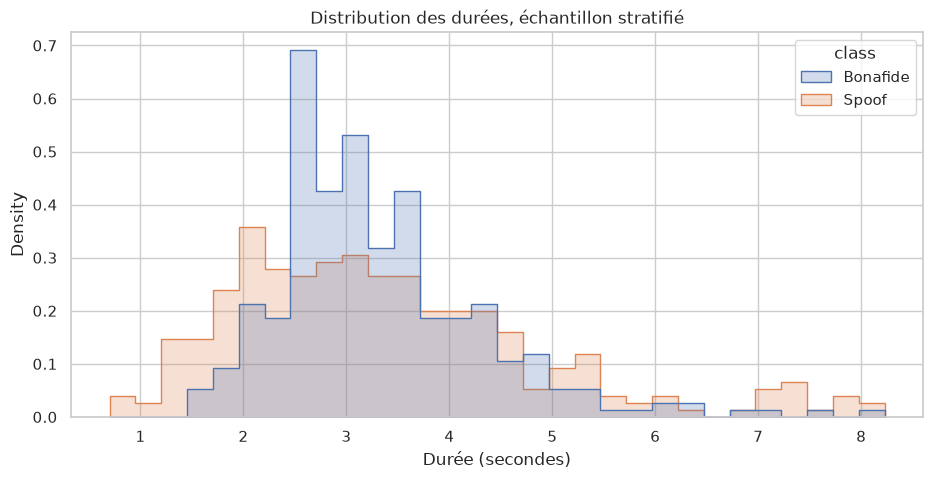

count  mean   std   min   25%   50%   75%   max
split      class                                                    
test       Bonafide  100.0  3.34  1.06  1.49  2.64  3.09  3.76  7.98
           Spoof     100.0  3.08  1.48  0.70  2.06  2.74  3.89  7.80
train      Bonafide  100.0  3.16  0.82  1.48  2.56  3.02  3.62  6.39
           Spoof     100.0  3.50  1.42  1.31  2.51  3.30  4.09  8.09
validation Bonafide  100.0  3.47  1.13  1.57  2.64  3.24  4.12  7.08
           Spoof     100.0  3.55  1.60  0.85  2.36  3.26  4.40  8.23

In [14]:
def decode_audio(dataset, idx):
    # On récupère l'exemple brut (pas encore décodé) et on le décode nous-mêmes.
    example = dataset[int(idx)]
    audio = example["audio"]
    if audio["bytes"] is not None:
        samples, sr = sf.read(io.BytesIO(audio["bytes"]), dtype="float32")
    else:
        samples, sr = sf.read(audio["path"], dtype="float32")
    return samples, sr, example

def sample_indices(dataset, n_per_class=100, seed=SEED):
    labels = np.asarray(dataset["key"])
    rng = np.random.default_rng(seed)
    indices = []
    for label in [0, 1]:
        candidates = np.where(labels == label)[0]
        selected = rng.choice(candidates, size=min(n_per_class, len(candidates)), replace=False)
        indices.extend(selected.tolist())
    return indices

ds_raw = {split: d.cast_column("audio", Audio(decode=False)) for split, d in ds.items()}

duration_rows = []
for split, dataset in ds_raw.items():
    for idx in sample_indices(dataset, n_per_class=100):
        samples, sr, example = decode_audio(dataset, idx)
        duration_rows.append({
            "split": split,
            "key": example["key"],
            "duration": len(samples) / sr,
        })

durations_df = pd.DataFrame(duration_rows)
durations_df["class"] = durations_df["key"].map(label_names)

plt.figure(figsize=(11, 5))
sns.histplot(data=durations_df, x="duration", hue="class", bins=30,
             element="step", stat="density", common_norm=False)
plt.xlabel("Durée (secondes)")
plt.title("Distribution des durées, échantillon stratifié")
plt.show()

durations_df.groupby(["split", "class"])["duration"].describe().round(2)


## 9. Écouter et regarder un bonafide et un spoof

On compare directement deux fichiers : un vrai (bonafide) et un faux généré par l'attaque A01, pour voir et entendre la différence.


In [15]:
train_ds = ds_raw["train"]
train_meta = metadata["train"]

bonafide_idx = train_meta.index[train_meta["key"] == 0][0]
spoof_idx = train_meta.index[train_meta["key"] == 1][0]

bonafide_signal, bonafide_sr, bonafide = decode_audio(train_ds, bonafide_idx)
spoof_signal, spoof_sr, spoof = decode_audio(train_ds, spoof_idx)

print("Bonafide :", bonafide["audio_file_name"])
print("Spoof :", spoof["audio_file_name"], "| system_id :", spoof["system_id"])

display(IPyAudio(bonafide_signal, rate=bonafide_sr))
display(IPyAudio(spoof_signal, rate=spoof_sr))


Bonafide : LA_T_1138215
Spoof : LA_T_1004644 | system_id : A01


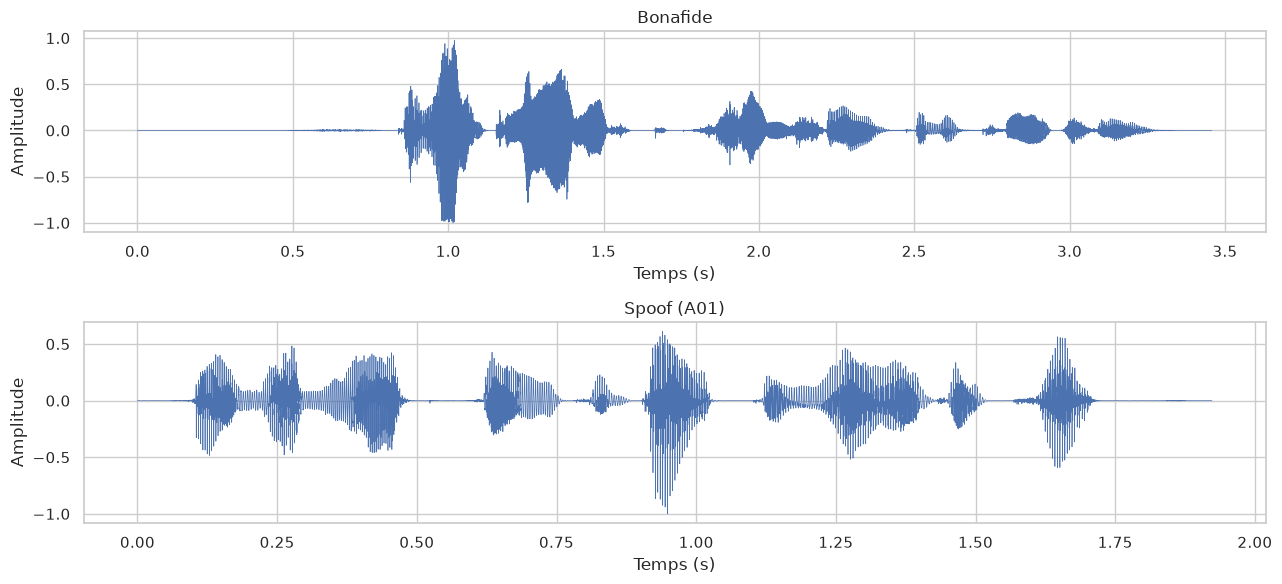

In [16]:
fig, axes = plt.subplots(2, 1, figsize=(13, 6))
pairs = [(bonafide_signal, bonafide_sr, "Bonafide"), (spoof_signal, spoof_sr, f"Spoof ({spoof['system_id']})")]
for ax, (signal, sr, title) in zip(axes, pairs):
    time = np.arange(len(signal)) / sr
    ax.plot(time, signal, linewidth=0.5)
    ax.set_title(title)
    ax.set_xlabel("Temps (s)")
    ax.set_ylabel("Amplitude")
plt.tight_layout()
plt.show()


## 10. FFT, STFT, mel spectrogramme et MFCC

Paramètres retenus pour le projet, cohérents avec `features.py` : `n_fft=1024`, `hop_length=256`, `n_mels=80`, sur un signal à 16kHz.

Il reste un point à trancher en équipe : Yaniss a utilisé un fenêtrage différent (`n_fft=512, hop_length=160, win_length=400`, le standard utilisé en reconnaissance vocale). Les deux réglages donnent des spectrogrammes de forme différente, donc il faut choisir UN seul réglage avant de figer `features.py`, sinon les modèles ne seront pas comparables entre eux.


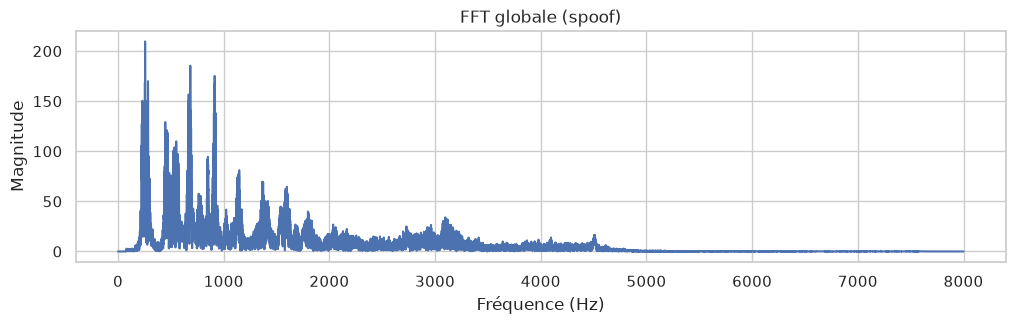

In [17]:
signal = spoof_signal
sr = spoof_sr

# FFT sur tout le clip, juste pour voir quelles fréquences dominent
x = torch.from_numpy(signal)
X = torch.fft.rfft(x)
freqs = torch.fft.rfftfreq(len(x), d=1 / sr)

plt.figure(figsize=(12, 3))
plt.plot(freqs, X.abs())
plt.xlabel("Fréquence (Hz)"); plt.ylabel("Magnitude")
plt.title("FFT globale (spoof)")
plt.show()


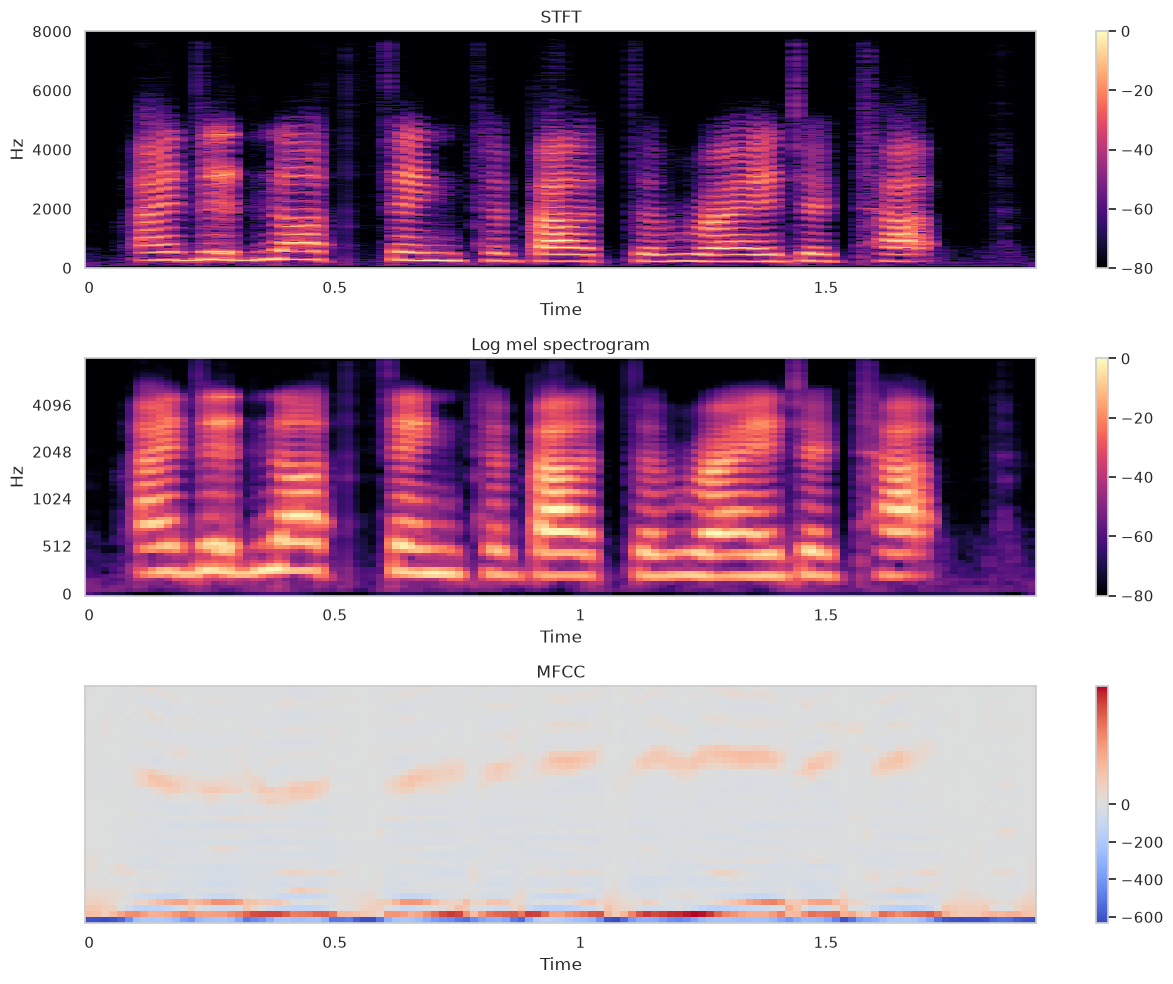

Shape STFT : (513, 121)
Shape log mel : (80, 121)
Shape MFCC : (40, 121)


In [18]:
# STFT, log mel et MFCC avec les paramètres retenus pour le projet
mel = librosa.feature.melspectrogram(y=signal, sr=sr, n_fft=1024, hop_length=256, n_mels=80)
log_mel = librosa.power_to_db(mel, ref=np.max)

stft = librosa.stft(signal, n_fft=1024, hop_length=256)
stft_db = librosa.amplitude_to_db(np.abs(stft), ref=np.max)

mfcc = librosa.feature.mfcc(y=signal, sr=sr, n_mfcc=40, n_fft=1024, hop_length=256)

fig, axes = plt.subplots(3, 1, figsize=(13, 10))
for ax, (data, title, y_axis) in zip(axes, [
    (stft_db, "STFT", "linear"),
    (log_mel, "Log mel spectrogram", "mel"),
    (mfcc, "MFCC", None),
]):
    img = librosa.display.specshow(data, sr=sr, hop_length=256, x_axis="time", y_axis=y_axis, ax=ax)
    ax.set_title(title)
    fig.colorbar(img, ax=ax)
plt.tight_layout()
plt.show()

print("Shape STFT :", stft_db.shape)
print("Shape log mel :", log_mel.shape)
print("Shape MFCC :", mfcc.shape)


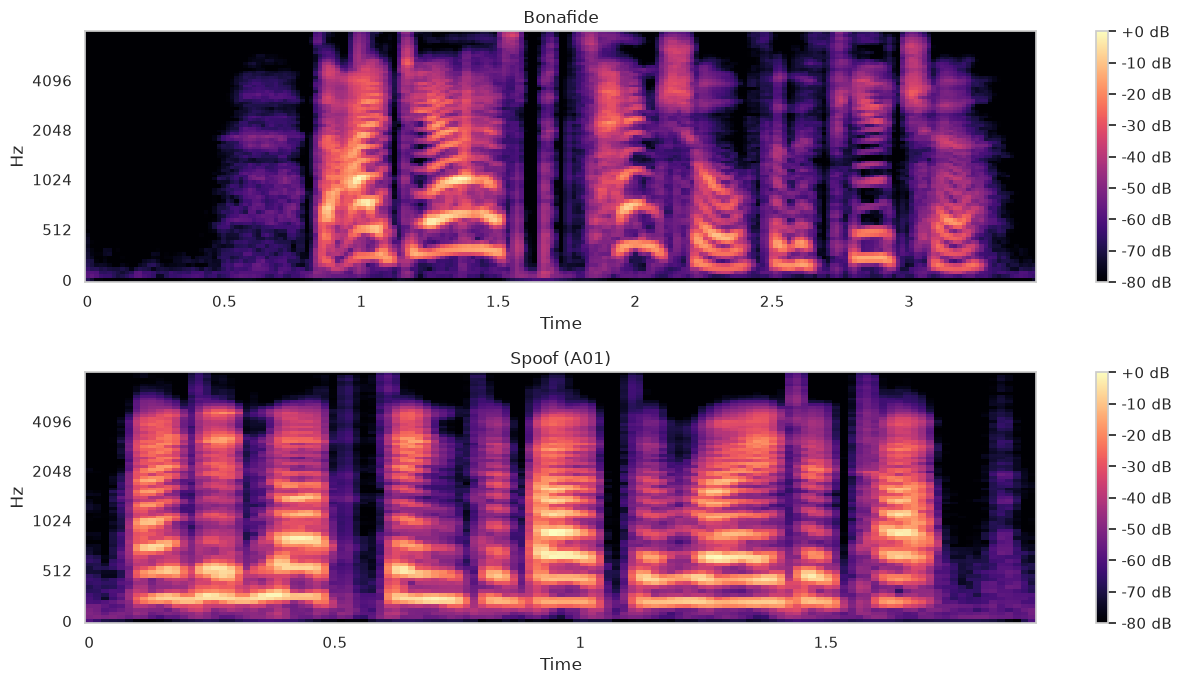

In [19]:
# Même log mel spectrogram, mais côte à côte pour bonafide et spoof
fig, axes = plt.subplots(2, 1, figsize=(13, 7))
pairs = [(bonafide_signal, bonafide_sr, "Bonafide"), (spoof_signal, spoof_sr, f"Spoof ({spoof['system_id']})")]
for ax, (sig, s_r, title) in zip(axes, pairs):
    mel_ex = librosa.feature.melspectrogram(y=sig, sr=s_r, n_fft=1024, hop_length=256, n_mels=80)
    log_mel_ex = librosa.power_to_db(mel_ex, ref=np.max)
    img = librosa.display.specshow(log_mel_ex, sr=s_r, hop_length=256, x_axis="time", y_axis="mel", ax=ax)
    ax.set_title(title)
    fig.colorbar(img, ax=ax, format="%+2.0f dB")
plt.tight_layout()
plt.show()


## 11. Ce qu'on retient

Le dataset ASVspoof2019 LA est propre et fiable, on peut s'en servir tel quel pour tout le projet.

Ce qu'on a vérifié :
- les locuteurs ne se recoupent pas entre les 3 splits ;
- les attaques sont bien séparées, A01 à A06 en train/validation, A07 à A19 en test ;
- aucun doublon ;
- les 121 461 fichiers sont tous à 16kHz, sans exception ;
- les durées sont courtes et homogènes, entre 1 et 6 secondes environ.

Le split test (attaques jamais vues à l'entraînement) nous sert déjà de test de généralisation, c'est le principe même du protocole ASVspoof, pas besoin d'aller chercher un autre dataset pour ça.

Ce qui reste à décider avant d'écrire `features.py` :
1. le réglage spectral à utiliser pour tout le monde (voir section 10) ;
2. comment gérer le déséquilibre des classes (weighted loss, sampler, ou les deux) ;
3. une baseline toute simple (prédire "spoof" à chaque fois) pour avoir un point de comparaison avant de juger les vrais modèles.
